<a href="https://colab.research.google.com/github/eliezermiranda/UFF_Deep_Learning/blob/main/03_Eliezer_Miranda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UNIVERSIDADE FEDERAL FLUMINENSE

**Introdução ao Aprendizado Profundo**

**Prof.: Diogo Ferreira de Lima Silva**

**Aluno: Eliezer Guimarães Miranda**

---
# AULA 03 — SUA PRIMEIRA REDE NEURAL
---

Na aula 2 treinamos uma **reta** com PyTorch. Hoje vamos trocar a reta por uma **rede neural** e ver que ela consegue aprender relações que uma reta não consegue.

**O que você vai aprender**

- montar uma rede neural com `nn.Sequential`;
- o que são **neurônios**, **camadas** e a **função de ativação** ReLU;
- escrever o laço de treinamento dentro de uma **função**, para reutilizá-lo;
- usar o modelo treinado para fazer previsões.

## 0. Importando as bibliotecas

In [137]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)      # fixa a semente: os resultados ficam iguais a cada execução

# cores usadas nos gráficos
LARANJA, AZUL, VERDE, VERMELHO, CINZA = "#E08D2B", "#1F7A8C", "#2E7D4F", "#B3151A", "#5B6472"

---
## 1. Dados
---

Vamos criar dados artificiais em que $y$ **sobe, desce e sobe de novo** conforme $x$ cresce. Pense, por exemplo, na demanda de um produto ao longo de um período, com altos e baixos.

A função `train_test_split` do scikit-learn separa os dados em **treino** (para o modelo aprender) e **teste** (para conferirmos se ele aprendeu de verdade).

In [138]:
from sklearn.model_selection import train_test_split

x = np.linspace(-3, 3, 120)                                  # 120 valores de x entre -3 e 3
y = np.sin(1.5 * x) + 0.3 * x + np.random.default_rng(42).normal(0, 0.15, 120)

x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.3, random_state=42)

print("exemplos de treino:", len(x_treino))
print("exemplos de teste :", len(x_teste))

exemplos de treino: 84
exemplos de teste : 36


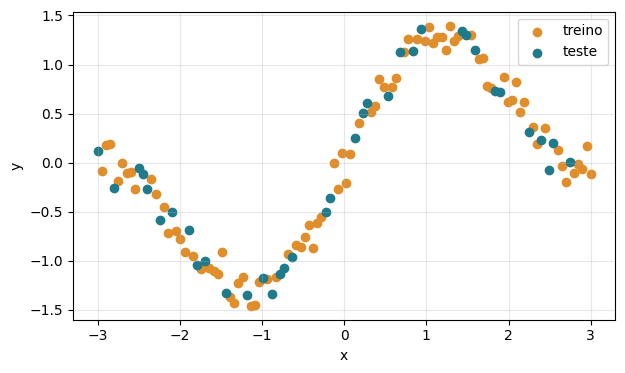

In [139]:
plt.figure(figsize=(7, 4))
plt.scatter(x_treino, y_treino, color=LARANJA, label="treino")
plt.scatter(x_teste, y_teste, color=AZUL, label="teste")
plt.xlabel("x"); plt.ylabel("y")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

---
## 2. Tensores
---

Como na aula passada: convertemos para tensores `float32` e usamos `.reshape(-1, 1)` para que cada **linha** seja um exemplo.

In [140]:
X_treino = torch.tensor(x_treino, dtype=torch.float32).reshape(-1, 1)
Y_treino = torch.tensor(y_treino, dtype=torch.float32).reshape(-1, 1)
X_teste  = torch.tensor(x_teste,  dtype=torch.float32).reshape(-1, 1)
Y_teste  = torch.tensor(y_teste,  dtype=torch.float32).reshape(-1, 1)

print("X_treino:", X_treino.shape)

X_treino: torch.Size([84, 1])


---
## 3. Primeira tentativa: uma reta
---

Começamos com o modelo da aula passada, `nn.Linear(1, 1)`, para ter uma referência.

Uma novidade: usaremos o otimizador **Adam** em vez do SGD. Ele ajusta o tamanho do passo automaticamente e costuma funcionar bem sem muitos ajustes. Vamos usá-lo como padrão daqui em diante.

In [141]:
reta = nn.Linear(1, 1)

perda_fn = nn.MSELoss() # erro quadrático médio
otimizador = torch.optim.Adam(reta.parameters(), lr=0.01)

for epoca in range(2000):
    previsao = reta(X_treino)               # 1. prever
    perda = perda_fn(previsao, Y_treino)    # 2. medir o erro
    otimizador.zero_grad()                  # 3. zerar os gradientes antigos
    perda.backward()                        # 4. calcular os gradientes
    otimizador.step()                       # 5. corrigir os parâmetros

print("perda final no treino:", perda.item())

perda final no treino: 0.47738465666770935


Para desenhar o modelo, pedimos previsões para muitos valores de $x$. O bloco `with torch.no_grad():` avisa ao PyTorch que **não** vamos treinar ali, apenas prever.

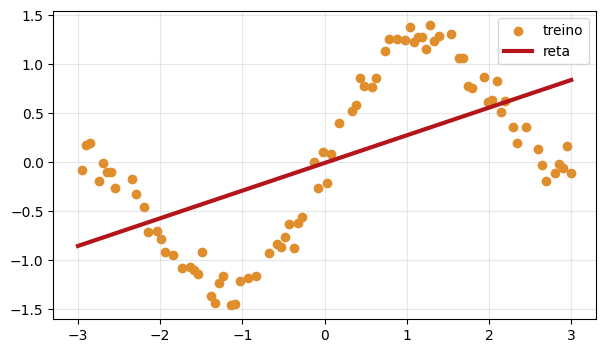

In [142]:
x_grade = torch.linspace(-3, 3, 200).reshape(-1, 1)     # 200 pontos para desenhar a curva (neste caso, uma reta)

with torch.no_grad():
    y_reta = reta(x_grade)

plt.figure(figsize=(7, 4))
plt.scatter(x_treino, y_treino, color=LARANJA, label="treino")
plt.plot(x_grade, y_reta, color=VERMELHO, linewidth=3, label="reta")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

A reta faz o melhor que pode, mas uma reta **nunca** vai subir, descer e subir de novo. Precisamos de um modelo mais flexível.

---
## 4. Uma rede neural
---

Criaremos uma rede neural rasa com os elementos a seguir?

```
entrada x  →  [ nn.Linear(1, 10) ]  →  [ nn.ReLU() ]  →  [ nn.Linear(10, 1) ]  →  saída y
               10 "neurônios"          ativação          junta os 10 em 1
```

- **`nn.Linear(1, 10)`**: transforma o $x$ em 10 números diferentes (cada um é uma reta com seus próprios parâmetros). Esses 10 números são as pré-ativações nos **neurônios** da **camada oculta**.
- **`nn.ReLU()`**: a **função de ativação**. Ela troca os números negativos por zero.
- **`nn.Linear(10, 1)`**: combina os 10 neurônios em uma única saída.

O `nn.Sequential` encaixa as peças na ordem em que aparecem.

### A função ReLU

A ReLU é muito simples: se o número é negativo, vira zero; se é positivo, fica como está.

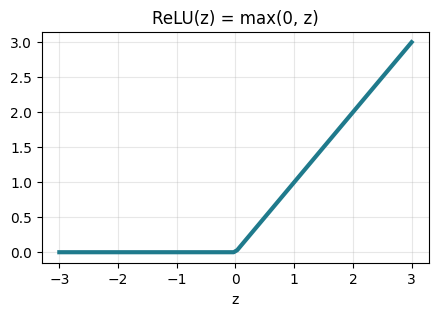

tensor([0., 0., 0., 1., 3.])


In [143]:
z = torch.linspace(-3, 3, 100)
relu = nn.ReLU()

plt.figure(figsize=(5, 3))
plt.plot(z, relu(z), color=AZUL, linewidth=3)
plt.title("ReLU(z) = max(0, z)"); plt.xlabel("z"); plt.grid(alpha=0.3)
plt.show()

print(relu(torch.tensor([-2.0, -0.5, 0.0, 1.0, 3.0])))

É justamente esse "dobrar" em zero que dá flexibilidade à rede: combinando várias retas dobradas, ela consegue formar curvas.

> **Por que não tirar a ReLU?** Sem ela, as duas camadas `nn.Linear` em sequência continuariam sendo, no fim das contas, uma reta. A ativação é o que torna a rede **não linear**.

### Montando a rede

In [144]:
rede = nn.Sequential(
    nn.Linear(1, 10),    # camada oculta: 10 neurônios
    nn.ReLU(),           # ativação
    nn.Linear(10, 1),    # camada de saída
)

print(rede)

Sequential(
  (0): Linear(in_features=1, out_features=10, bias=True)
  (1): ReLU()
  (2): Linear(in_features=10, out_features=1, bias=True)
)


Quantos parâmetros essa rede tem? O método `.parameters()` devolve todos eles, e `.numel()` conta quantos números há em cada um.

In [145]:
total = 0
for p in rede.parameters():
    print(p.shape)
    total = total + p.numel()

print("total de parâmetros:", total)

torch.Size([10, 1])
torch.Size([10])
torch.Size([1, 10])
torch.Size([1])
total de parâmetros: 31


A reta tinha 2 parâmetros. A rede tem 31. Mais parâmetros = mais flexibilidade.

---
## 5. Treinando a rede
---

Repare: o laço de treinamento é **exatamente o mesmo** da reta. Só trocamos `reta` por `rede`.

In [146]:
perda_fn = nn.MSELoss()
otimizador = torch.optim.Adam(rede.parameters(), lr=0.01)

for epoca in range(2000):
    previsao = rede(X_treino)
    perda = perda_fn(previsao, Y_treino)
    otimizador.zero_grad()
    perda.backward()
    otimizador.step()

    if epoca % 500 == 0:                     # mostra o progresso a cada 500 épocas
        print(f"época {epoca:4d} | perda = {perda.item():.4f}")

print("perda final no treino:", perda.item())

época    0 | perda = 0.4980
época  500 | perda = 0.0146
época 1000 | perda = 0.0141
época 1500 | perda = 0.0140
perda final no treino: 0.014045573770999908


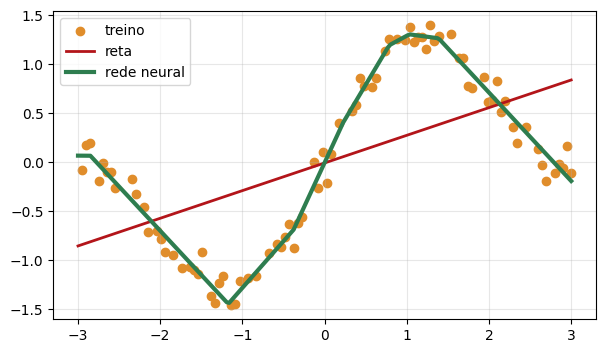

In [147]:
with torch.no_grad():
    y_rede = rede(x_grade)

plt.figure(figsize=(7, 4))
plt.scatter(x_treino, y_treino, color=LARANJA, label="treino")
plt.plot(x_grade, y_reta, color=VERMELHO, linewidth=2, label="reta")
plt.plot(x_grade, y_rede, color=VERDE, linewidth=3, label="rede neural")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

### Avaliando no teste

Para analisar se o modelo é capaz de generalizar para dados desconhecidos, utilizamos o conjunto de teste.

In [148]:
with torch.no_grad():
    erro_reta = perda_fn(reta(X_teste), Y_teste).item()
    erro_rede = perda_fn(rede(X_teste), Y_teste).item()

print(f"erro no teste (MSE) - reta: {erro_reta:.4f}")
print(f"erro no teste (MSE) - rede: {erro_rede:.4f}")

erro no teste (MSE) - reta: 0.4664
erro no teste (MSE) - rede: 0.0165


---
## 6. Guardando o treinamento em uma função
---

Vamos treinar várias redes daqui para frente. Para não copiar o laço toda vez, podemos colocar ele dentro de uma **função** no python. A função recebe o modelo, os dados e o número de épocas, treina, e devolve a lista com a perda de cada época.

In [149]:
def treinar(modelo, X, Y, epocas=2000, lr=0.01):
    perda_fn = nn.MSELoss()
    otimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    historico = []

    for epoca in range(epocas):
        previsao = modelo(X)
        perda = perda_fn(previsao, Y)
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()
        historico.append(perda.item())     # guarda a perda desta época

    return historico

Com a função, treinar uma rede nova fica em duas linhas:

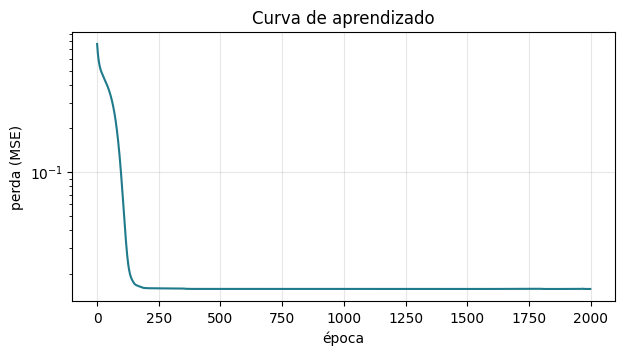

In [150]:
rede2 = nn.Sequential(nn.Linear(1, 10), nn.ReLU(), nn.Linear(10, 1))
historico = treinar(rede2, X_treino, Y_treino)

plt.figure(figsize=(7, 3.5))
plt.plot(historico, color=AZUL)
plt.xlabel("época"); plt.ylabel("perda (MSE)"); plt.title("Curva de aprendizado")
plt.yscale("log"); plt.grid(alpha=0.3)
plt.show()

A **curva de aprendizado** mostra a perda caindo ao longo das épocas. É a primeira coisa a olhar quando treinamos um modelo: se ela não cai, algo está errado.

---
## 7. Quantos neurônios usar?
---

O número de neurônios da camada oculta é uma escolha nossa. Vamos comparar 1, 3, 10 e 100 neurônios.

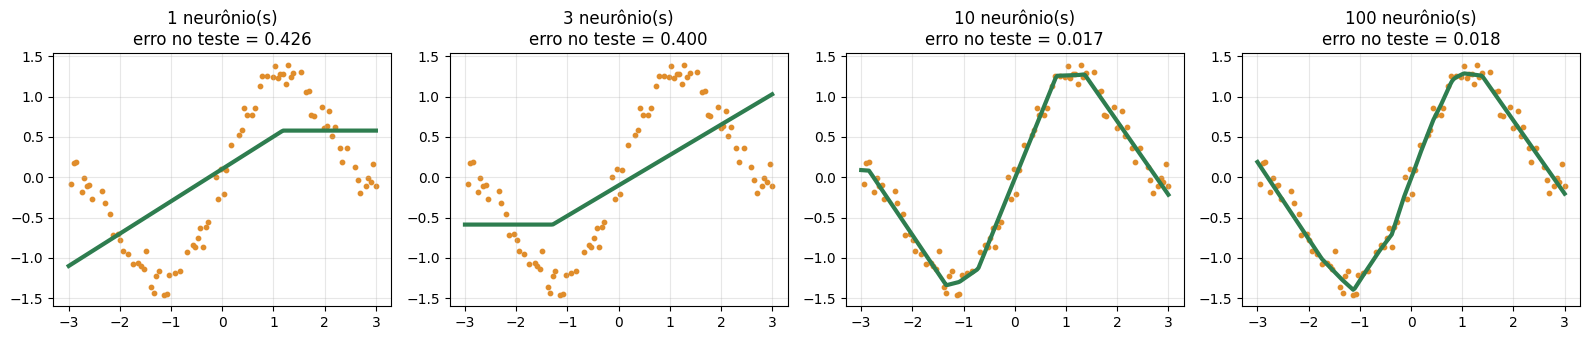

In [151]:
fig, eixos = plt.subplots(1, 4, figsize=(16, 3.5))

for eixo, n in zip(eixos, [1, 3, 10, 100]):
    torch.manual_seed(42)
    modelo = nn.Sequential(nn.Linear(1, n), nn.ReLU(), nn.Linear(n, 1))
    treinar(modelo, X_treino, Y_treino)

    with torch.no_grad():
        erro_teste = perda_fn(modelo(X_teste), Y_teste).item()
        eixo.plot(x_grade, modelo(x_grade), color=VERDE, linewidth=3)

    eixo.scatter(x_treino, y_treino, color=LARANJA, s=10)
    eixo.set_title(f"{n} neurônio(s)\nerro no teste = {erro_teste:.3f}")
    eixo.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Com **1 ou 3 neurônios**, a rede não acompanha a curva: há poucas "dobras" disponíveis. Com tão poucos neurônios, basta um deles ficar inativo (sempre zerado pela ReLU) para a rede perder a flexibilidade.
- A partir de **10 neurônios**, o ajuste fica bom.
- Ir para **100 neurônios** não melhora o teste: mais parâmetros do que o problema precisa não ajudam.

Escolher o tamanho da rede é uma decisão prática que voltará várias vezes no curso.

---
## 8. Usando o modelo para prever
---

Depois de treinado, o modelo funciona como uma função comum: damos um $x$, ele devolve um $y$.

In [152]:
novos_x = torch.tensor([[-2.0], [0.0], [1.0], [2.5]])

with torch.no_grad():
    previsoes = rede(novos_x)

for xv, yv in zip(novos_x, previsoes):
    print(f"x = {xv.item():5.1f}  ->  y previsto = {yv.item():6.3f}")

x =  -2.0  ->  y previsto = -0.698
x =   0.0  ->  y previsto = -0.004
x =   1.0  ->  y previsto =  1.289
x =   2.5  ->  y previsto =  0.259


---
## Exercícios
---

**1.** Troque `nn.ReLU()` por `nn.Tanh()` na rede da Seção 4 e treine de novo. A curva ficou diferente? Como?

**2.** Treine a rede com apenas 200 épocas em vez de 2000. O que acontece com o ajuste?

**3.** Crie uma rede com **duas** camadas ocultas de 10 neurônios. Dica: acrescente mais um `nn.Linear(10, 10)` e mais um `nn.ReLU()` no `nn.Sequential`.

**4.** Use a rede treinada para prever $y$ em $x = 10$, um valor bem fora dos dados de treino. O resultado faz sentido?

==================================================================================================

# EXERCÍCIO 1 — Troque nn.ReLU() por nn.Tanh() na rede da Seção 4 e treine de novo.

A curva ficou diferente? Como?

==================================================================================================

In [153]:
# ==================================================================================================================
# EXERCÍCIO 1 — Troque nn.ReLU() por nn.Tanh() na rede da Seção 4 e treine de novo. A curva ficou diferente? Como?
# ==================================================================================================================

rede_tanh = nn.Sequential(
    nn.Linear(1, 10),    # camada oculta: 10 neurônios
    nn.Tanh(),           # ativação Tanh no lugar da ReLU
    nn.Linear(10, 1),    # camada de saída
)

print(rede_tanh)

Sequential(
  (0): Linear(in_features=1, out_features=10, bias=True)
  (1): Tanh()
  (2): Linear(in_features=10, out_features=1, bias=True)
)


In [154]:
perda_fn = nn.MSELoss()
otimizador = torch.optim.Adam(rede_tanh.parameters(), lr=0.01)

for epoca in range(2000):
    previsao = rede_tanh(X_treino)
    perda = perda_fn(previsao, Y_treino)
    otimizador.zero_grad()
    perda.backward()
    otimizador.step()

    if epoca % 500 == 0:                     # mostra o progresso a cada 500 épocas
        print(f"época {epoca:4d} | perda = {perda.item():.4f}")

print("perda final no treino:", perda.item())

época    0 | perda = 0.9564
época  500 | perda = 0.0150
época 1000 | perda = 0.0139
época 1500 | perda = 0.0138
perda final no treino: 0.013677241280674934


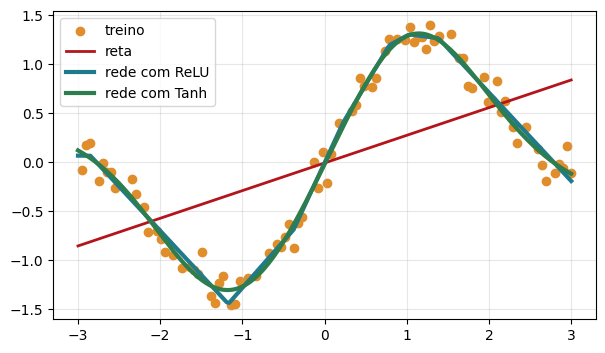

In [155]:
with torch.no_grad():
    y_tanh = rede_tanh(x_grade)

plt.figure(figsize=(7, 4))
plt.scatter(x_treino, y_treino, color=LARANJA, label="treino")
plt.plot(x_grade, y_reta, color=VERMELHO, linewidth=2, label="reta")
plt.plot(x_grade, y_rede, color=AZUL, linewidth=3, label="rede com ReLU")
plt.plot(x_grade, y_tanh, color=VERDE, linewidth=3, label="rede com Tanh")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [156]:
with torch.no_grad():
    erro_tanh = perda_fn(rede_tanh(X_teste), Y_teste).item()

print(f"erro no teste (MSE) - rede ReLU: {erro_rede:.4f}")
print(f"erro no teste (MSE) - rede Tanh: {erro_tanh:.4f}")

erro no teste (MSE) - rede ReLU: 0.0165
erro no teste (MSE) - rede Tanh: 0.0137


------------------------------------------------------------
RESPOSTA EXERCÍCIO 01:

Sim, a curva ficou diferente.

- Com a ReLU, a curva é feita de vários pedaços de reta ligados entre si, então ela tem "quinas".
- Com a Tanh, a curva é lisa e arredondada, sem quinas. Isso acontece porque a Tanh é uma função suave, em forma de "S".

Mesmo com formatos um pouco diferentes, as duas redes aprenderam bem os dados. O erro no teste foi parecido: 0,0165 com ReLU e 0,0137 com Tanh.

------------------------------------------------------------

===============================================================================================


# EXERCÍCIO 2 — Treine a rede com apenas 200 épocas em vez de 2000.

O que acontece com o ajuste?

===============================================================================================

In [157]:
# ===============================================================================================
# EXERCÍCIO 2 — Treine a rede com apenas 200 épocas em vez de 2000. O que acontece com o ajuste?
# ===============================================================================================

rede_200 = nn.Sequential(
    nn.Linear(1, 10),    # camada oculta: 10 neurônios
    nn.ReLU(),           # ativação
    nn.Linear(10, 1),    # camada de saída
)

print(rede_200)

Sequential(
  (0): Linear(in_features=1, out_features=10, bias=True)
  (1): ReLU()
  (2): Linear(in_features=10, out_features=1, bias=True)
)


In [158]:
perda_fn = nn.MSELoss()
otimizador = torch.optim.Adam(rede_200.parameters(), lr=0.01)

for epoca in range(200):                     # 200 épocas em vez de 2000
    previsao = rede_200(X_treino)
    perda = perda_fn(previsao, Y_treino)
    otimizador.zero_grad()
    perda.backward()
    otimizador.step()

    if epoca % 50 == 0:                      # mostra o progresso a cada 50 épocas
        print(f"época {epoca:4d} | perda = {perda.item():.4f}")

print("perda final no treino:", perda.item())

época    0 | perda = 0.9058
época   50 | perda = 0.2604
época  100 | perda = 0.0321
época  150 | perda = 0.0170
perda final no treino: 0.016358213499188423


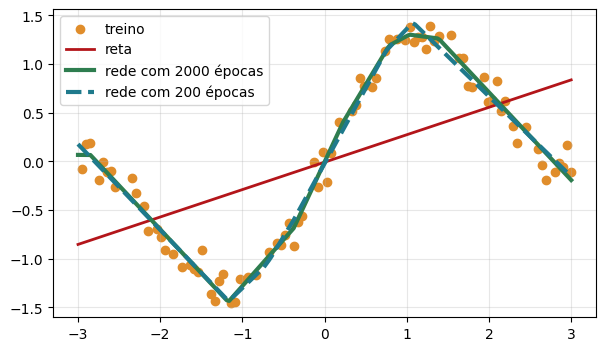

In [159]:
with torch.no_grad():
    y_200 = rede_200(x_grade)

plt.figure(figsize=(7, 4))
plt.scatter(x_treino, y_treino, color=LARANJA, label="treino")
plt.plot(x_grade, y_reta, color=VERMELHO, linewidth=2, label="reta")
plt.plot(x_grade, y_rede, color=VERDE, linewidth=3, label="rede com 2000 épocas")
plt.plot(x_grade, y_200, color=AZUL, linewidth=3, linestyle="--", label="rede com 200 épocas")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [160]:
with torch.no_grad():
    erro_200 = perda_fn(rede_200(X_teste), Y_teste).item()

print(f"erro no teste (MSE) - rede com 2000 épocas: {erro_rede:.4f}")
print(f"erro no teste (MSE) - rede com 200 épocas : {erro_200:.4f}")

erro no teste (MSE) - rede com 2000 épocas: 0.0165
erro no teste (MSE) - rede com 200 épocas : 0.0187


------------------------------------------------------------

RESPOSTA EXERCÍCIO 02:

Com apenas 200 épocas, a rede treinou por menos tempo e por isso aprendeu um pouco menos.

- Perda final no treino: 0,0164 com 200 épocas, contra 0,0140 com 2000 épocas.
- Erro no teste: 0,0187 com 200 épocas, contra 0,0165 com 2000 épocas.

No gráfico, a curva da rede com 200 épocas fica bem parecida com a de 2000 épocas e segue o formato geral dos dados (desce, sobe e desce). Mesmo assim, ela se ajusta um pouco pior aos picos e vales, e os erros de treino e de teste ficaram maiores.

Os valores da perda impressos durante o treino mostram que o erro ainda estava diminuindo quando o treino parou. Ou seja, a rede ainda podia aprender mais. Quando isso acontece, dizemos que o modelo está subajustado (underfitting). A solução, nesse caso, é treinar por mais épocas.

------------------------------------------------------------

==================================================================================

# EXERCÍCIO 3 — Crie uma rede com duas camadas ocultas de 10 neurônios.

Dica: acrescente mais um nn.Linear(10, 10) e mais um nn.ReLU() no nn.Sequential.

==================================================================================

In [161]:
# ==================================================================================
# EXERCÍCIO 3 — Crie uma rede com duas camadas ocultas de 10 neurônios.
# Dica: acrescente mais um nn.Linear(10, 10) e mais um nn.ReLU() no nn.Sequential.
# ==================================================================================

rede_2camadas = nn.Sequential(
    nn.Linear(1, 10),    # 1ª camada oculta: 10 neurônios
    nn.ReLU(),           # ativação
    nn.Linear(10, 10),   # 2ª camada oculta: 10 neurônios
    nn.ReLU(),           # ativação
    nn.Linear(10, 1),    # camada de saída
)

print(rede_2camadas)

Sequential(
  (0): Linear(in_features=1, out_features=10, bias=True)
  (1): ReLU()
  (2): Linear(in_features=10, out_features=10, bias=True)
  (3): ReLU()
  (4): Linear(in_features=10, out_features=1, bias=True)
)


In [162]:
total = 0
for p in rede_2camadas.parameters():
    print(p.shape)
    total = total + p.numel()

print("total de parâmetros:", total)

torch.Size([10, 1])
torch.Size([10])
torch.Size([10, 10])
torch.Size([10])
torch.Size([1, 10])
torch.Size([1])
total de parâmetros: 141


In [163]:
perda_fn = nn.MSELoss()
otimizador = torch.optim.Adam(rede_2camadas.parameters(), lr=0.01)

for epoca in range(2000):
    previsao = rede_2camadas(X_treino)
    perda = perda_fn(previsao, Y_treino)
    otimizador.zero_grad()
    perda.backward()
    otimizador.step()

    if epoca % 500 == 0:                     # mostra o progresso a cada 500 épocas
        print(f"época {epoca:4d} | perda = {perda.item():.4f}")

print("perda final no treino:", perda.item())

época    0 | perda = 0.5691
época  500 | perda = 0.0124
época 1000 | perda = 0.0118
época 1500 | perda = 0.0112
perda final no treino: 0.011555572040379047


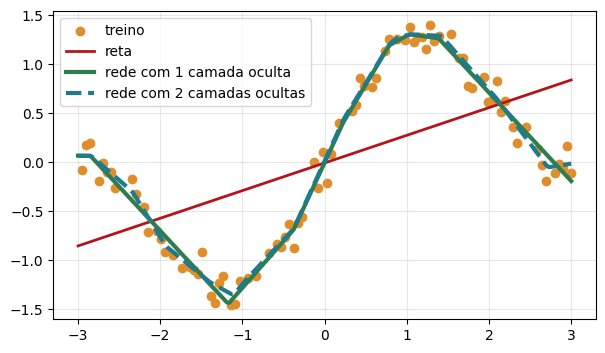

In [164]:
with torch.no_grad():
    y_2camadas = rede_2camadas(x_grade)

plt.figure(figsize=(7, 4))
plt.scatter(x_treino, y_treino, color=LARANJA, label="treino")
plt.plot(x_grade, y_reta, color=VERMELHO, linewidth=2, label="reta")
plt.plot(x_grade, y_rede, color=VERDE, linewidth=3, label="rede com 1 camada oculta")
plt.plot(x_grade, y_2camadas, color=AZUL, linewidth=3, linestyle="--", label="rede com 2 camadas ocultas")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [165]:
with torch.no_grad():
    erro_2camadas = perda_fn(rede_2camadas(X_teste), Y_teste).item()

print(f"erro no teste (MSE) - rede com 1 camada oculta : {erro_rede:.4f}")
print(f"erro no teste (MSE) - rede com 2 camadas ocultas: {erro_2camadas:.4f}")

erro no teste (MSE) - rede com 1 camada oculta : 0.0165
erro no teste (MSE) - rede com 2 camadas ocultas: 0.0149


------------------------------------------------------------

RESPOSTA EXERCÍCIO 03:

A nova rede tem duas camadas ocultas de 10 neurônios cada. Por isso ela tem 141 parâmetros, contra 31 da rede original com uma camada:
- 1ª camada oculta: 10 pesos + 10 vieses = 20
- 2ª camada oculta: 100 pesos + 10 vieses = 110
- camada de saída: 10 pesos + 1 viés = 11

No gráfico, as duas redes seguem bem os dados, e as curvas ficam bem parecidas.

O erro no teste foi 0,0149 com duas camadas, contra 0,0165 com uma camada. Ou seja, a diferença foi pequena.

Isso acontece porque o problema é simples: uma única camada com 10 neurônios já consegue representar bem essa curva. Colocar mais uma camada deixa a rede mais flexível, mas aqui isso não traz muito ganho. Redes com mais camadas costumam ajudar mais em problemas mais complicados.

------------------------------------------------------------

========================================================================================================

# EXERCÍCIO 4 — Use a rede treinada para prever  y  em  x=10 , um valor bem fora dos dados de treino.

O resultado faz sentido?


========================================================================================================

In [166]:
# ============================================================================================================================
# EXERCÍCIO 4 — Use a rede treinada para prever  y  em  x=10 , um valor bem fora dos dados de treino. O resultado faz sentido?
# ============================================================================================================================
# ============================================================================================================================
# EXERCÍCIO 4 - A — Com função de ativação ReLU (Rede da Seção 4)
# ============================================================================================================================

novos_x = torch.tensor([[1.0], [10.0]])     # x = 1 está dentro da faixa de treino; x = 10 está bem fora

with torch.no_grad():
    previsoes_relu = rede(novos_x)

for xv, yv in zip(novos_x, previsoes_relu):
    y_real = np.sin(1.5 * xv.item()) + 0.3 * xv.item()     # valor real, sem ruído
    print(f"x = {xv.item():5.1f}  ->  y previsto = {yv.item():6.3f}  |  y real = {y_real:6.3f}")


x =   1.0  ->  y previsto =  1.289  |  y real =  1.297
x =  10.0  ->  y previsto = -6.501  |  y real =  3.650


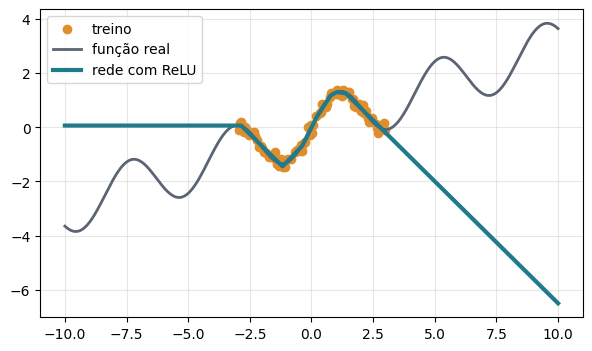

In [167]:
x_longe = torch.linspace(-10, 10, 400).reshape(-1, 1)     # 400 pontos entre -10 e 10

with torch.no_grad():
    y_longe_relu = rede(x_longe)

y_longe_real = torch.sin(1.5 * x_longe) + 0.3 * x_longe     # função real, sem ruído

plt.figure(figsize=(7, 4))
plt.scatter(x_treino, y_treino, color=LARANJA, label="treino")
plt.plot(x_longe, y_longe_real, color=CINZA, linewidth=2, label="função real")
plt.plot(x_longe, y_longe_relu, color=AZUL, linewidth=3, label="rede com ReLU")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

------------------------------------------------------------

RESPOSTA EXERCÍCIO 04-A (com a função de ativação ReLU):

O resultado não faz sentido.

- Em x = 1 (dentro da faixa de treino), a rede previu 1,289, bem perto do valor real de 1,297.
- Em x = 10 (fora da faixa de treino), a rede previu −6,501, muito longe do valor real de 3,650. A rede errou até o sinal.

A rede só viu dados entre x = −3 e x = 3, então só aprendeu o comportamento dos dados nessa faixa.

No gráfico, dá para ver que, depois do fim dos dados, a rede com ReLU simplesmente continua em linha reta. Ela não sabe que a função real continua subindo e descendo. Por isso, quanto mais longe dos dados, maior o erro.

Conclusão: a rede funciona bem para prever valores dentro da faixa dos dados de treino, mas não é confiável para prever valores muito fora dessa faixa.

------------------------------------------------------------

In [168]:
# ============================================================================================================================
# EXERCÍCIO 4 — Use a rede treinada para prever  y  em  x=10 , um valor bem fora dos dados de treino. O resultado faz sentido?
# ============================================================================================================================
# ============================================================================================================================
# EXERCÍCIO 4 - B — Com função de ativação Tanh (Rede do exercício 1)
# ============================================================================================================================

novos_x = torch.tensor([[1.0], [10.0]])     # x = 1 está dentro da faixa de treino; x = 10 está bem fora

with torch.no_grad():
    previsoes_tanh = rede_tanh(novos_x)

for xv, yv in zip(novos_x, previsoes_tanh):
    y_real = np.sin(1.5 * xv.item()) + 0.3 * xv.item()     # valor real, sem ruído
    print(f"x = {xv.item():5.1f}  ->  y previsto = {yv.item():6.3f}  |  y real = {y_real:6.3f}")

x =   1.0  ->  y previsto =  1.285  |  y real =  1.297
x =  10.0  ->  y previsto = -0.108  |  y real =  3.650


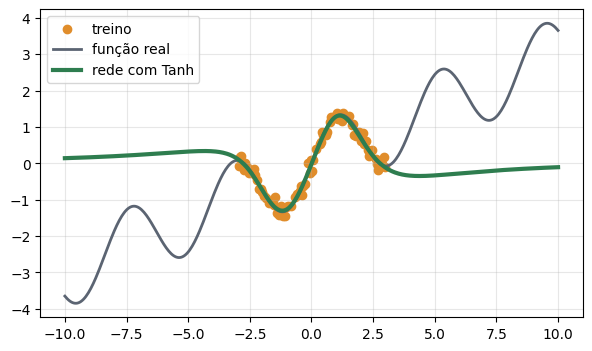

In [169]:
x_longe = torch.linspace(-10, 10, 400).reshape(-1, 1)     # 400 pontos entre -10 e 10

with torch.no_grad():
    y_longe_tanh = rede_tanh(x_longe)

y_longe_real = torch.sin(1.5 * x_longe) + 0.3 * x_longe     # função real, sem ruído

plt.figure(figsize=(7, 4))
plt.scatter(x_treino, y_treino, color=LARANJA, label="treino")
plt.plot(x_longe, y_longe_real, color=CINZA, linewidth=2, label="função real")
plt.plot(x_longe, y_longe_tanh, color=VERDE, linewidth=3, label="rede com Tanh")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

------------------------------------------------------------

RESPOSTA EXERCÍCIO 04-B (com a função de ativação Tanh):

O resultado também não faz sentido.

- Em x = 1 (dentro da faixa de treino), a rede previu 1,285, bem perto do valor real de 1,297.
- Em x = 10 (fora da faixa de treino), a rede previu −0,108, muito longe do valor real de 3,650.

Assim como a rede com ReLU, esta rede só viu dados entre x = −3 e x = 3.

No gráfico, dá para ver que, longe dos dados, a rede com Tanh fica quase reta e horizontal, ou seja, a previsão quase não muda. Isso acontece porque a Tanh nunca passa de −1 nem de +1. Para valores grandes de x, os neurônios ficam "travados" perto desses limites, e a saída da rede fica praticamente constante.

Conclusão: com Tanh o comportamento fora dos dados é diferente do da ReLU (fica constante em vez de seguir em linha reta), mas o problema é o mesmo: a rede não é confiável para prever valores muito fora da faixa dos dados de treino.

------------------------------------------------------------